<a class="anchor" id="0"></a>
# **Clasificador de máquinas de vectores de soporte (SVM) con Python**

En este cuaderno se entrena un clasificador SVM para distinguir **candidatos a púlsar** reales de ruido o señales espurias, usando el conjunto de datos **Predicting a Pulsar Star** (HTRU2).

Comience ejecutando las celdas en orden (en Google Colab: **Entorno de ejecución → Ejecutar todo** tras subir el CSV).


*Material educativo — ML Finanzas (Clase 9).*


<a class="anchor" id="0.1"></a>
# **Índice**

1. [Introducción a las máquinas de vectores de soporte](#1)
2. [Intuición de las SVM](#2)
3. [Truco del núcleo (*kernel trick*)](#3)
4. [SVM en Scikit-Learn](#4)
5. [Descripción del conjunto de datos](#5)
6. [Importar librerías](#6)
7. [Cargar el conjunto de datos](#7)
8. [Análisis exploratorio](#8)
9. [Matriz de características y variable objetivo](#9)
10. [Partición entrenamiento / prueba](#10)
11. [Escalado de características](#11)
12. [SVM con hiperparámetros por defecto](#12)
13. [SVM con núcleo lineal](#13)
14. [SVM con núcleo polinomial](#14)
15. [SVM con núcleo sigmoide](#15)
16. [Matriz de confusión](#16)
17. [Métricas de clasificación](#17)
18. [Curva ROC y AUC](#18)
19. [Validación cruzada k-fold con mezcla (*shuffle*)](#19)
20. [Optimización de hiperparámetros con GridSearchCV](#20)
21. [Resultados y conclusiones](#21)
22. [Referencias](#22)


# **1. Introducción a las máquinas de vectores de soporte** <a class="anchor" id="1"></a>

[Índice](#0.1)

Las **máquinas de vectores de soporte** (SVM, por sus siglas en inglés) son algoritmos de aprendizaje supervisado para clasificación y regresión. Son muy utilizados en clasificación, regresión y detección de valores atípicos. Un clasificador SVM construye un modelo que asigna nuevas observaciones a una de las categorías; en el caso binario lineal puede verse como un clasificador lineal no probabilístico.

El algoritmo original fue desarrollado por Vladimir N. Vapnik y Alexey Ya. Chervonenkis en 1963. En 1992, Boser, Guyon y Vapnik propusieron clasificadores no lineales mediante el **truco del núcleo** aplicado a hiperplanos de margen máximo. La formulación estándar actual se debe en gran parte a Cortes y Vapnik (1993, publicada en 1995).

Las SVM permiten clasificación lineal y, mediante el **truco del núcleo**, proyectan implícitamente los datos a espacios de mayor dimensión donde una separación lineal puede ser más adecuada.




# **2. Intuición de las SVM** <a class="anchor" id="2"></a>

[Índice](#0.1)

### Hiperplano

Un hiperplano es una frontera de decisión que separa puntos con distintas etiquetas de clase. La SVM busca un hiperplano con **margen máximo** entre las clases. Ese hiperplano se denomina `hiperplano de margen máximo` y el clasificador lineal asociado, `clasificador de margen máximo`.

### Vectores de soporte

Los vectores de soporte son los puntos del entrenamiento más cercanos al hiperplano; definen la frontera y el margen.

### Margen

El margen es la separación entre las fronteras paralelas más cercanas a los datos de cada clase (distancia perpendicular al hiperplano). En las SVM se **maximiza** ese margen.

El siguiente diagrama ilustra estos conceptos.

### Margen en una SVM

![Margen en SVM](https://static.wixstatic.com/media/8f929f_7ecacdcf69d2450087cb4a898ef90837~mv2.png)

### Idea interna de la SVM

El objetivo es elegir el hiperplano que maximiza el margen respecto a los vectores de soporte. En dos pasos:

1. Generar hiperplanos que separen las clases lo mejor posible; entre muchos candidatos, interesa el que deje el mayor margen entre clases.

2. Elegir el hiperplano cuya distancia a los vectores de soporte a cada lado sea máxima. Si existe, es el **hiperplano de margen máximo** y el clasificador asociado es el **clasificador de margen máximo**.

### Hiperplano de margen máximo

![Hiperplano de margen máximo](https://static.packt-cdn.com/products/9781783555130/graphics/3547_03_07.jpg)

### Datos no linealmente separables

A veces los puntos están tan mezclados que no existe un hiperplano lineal que los separe. Entonces la SVM usa el **truco del núcleo** para mapear los datos a un espacio de mayor dimensión donde sí sea posible una separación (casi) lineal.

### Truco del núcleo: espacio de mayor dimensión

![Truco del núcleo](http://www.aionlinecourse.com/uploads/tutorials/2019/07/11_21_kernel_svm_3.png)



# **3. Truco del núcleo** <a class="anchor" id="3"></a>

[Índice](#0.1)

En la práctica, la SVM se implementa eligiendo un **núcleo** (*kernel*). El **truco del núcleo** consiste en usar una función que envía los datos a un espacio donde las clases resultan más separables. Así, problemas no linealmente separables en el espacio original pueden volverse linealmente separables en un espacio ampliado, lo que suele mejorar el clasificador.



Podemos definir conceptualmente una función de núcleo como sigue:

### Función de núcleo

![Función de núcleo](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTodZptqcRor0LGo8Qn7_kJB9n9BACMt6jgIPZ4C3g_rgh_uSRZLQ&s)

En el contexto de las SVM son habituales cuatro núcleos: **lineal**, **polinomial**, **RBF** (función de base radial, también llamado gaussiano) y **sigmoide**. A continuación se resumen.

## **3.1 Núcleo lineal**

En el núcleo lineal, la función de núcleo tiene forma lineal:

**Núcleo lineal: K(xᵢ, xⱼ) = xᵢᵀ xⱼ**

Se usa cuando los datos son (aproximadamente) linealmente separables. Es muy común y a menudo adecuado cuando hay muchas características. También es frecuente en clasificación de texto.

Entrenar con núcleo lineal suele ser más rápido: solo hay que ajustar en profundidad el parámetro de regularización **C**. Con otros núcleos suele ajustarse también **γ** (*gamma*), y una búsqueda en rejilla puede costar más.

### Núcleo lineal (ilustración)

![Núcleo lineal](https://scikit-learn.org/stable/_images/sphx_glr_plot_svm_kernels_thumb.png)

## **3.2 Núcleo polinomial**

El núcleo polinomial mide la similitud en un espacio de características polinómicas construido a partir de las variables originales; considera no solo los atributos sino ciertas interacciones entre muestras.

Para polinomios de grado d:

**Núcleo polinomial: K(xᵢ, xⱼ) = (γ xᵢᵀ xⱼ + r)ᵈ , γ > 0**

Es habitual en PLN; un grado frecuente es d = 2 (cuadrático), porque grados mayores tienden a sobreajustar en tareas de texto.

### Núcleo polinomial (ilustración)

![Núcleo polinomial](https://www.researchgate.net/profile/Cheng_Soon_Ong/publication/23442384/figure/fig12/AS:341444054274063@1458418014823/The-effect-of-the-degree-of-a-polynomial-kernel-The-polynomial-kernel-of-degree-1-leads.png)

## **3.3 Núcleo de función de base radial (RBF)**

El núcleo de función de base radial (RBF) es de propósito general. Se utiliza cuando no tenemos conocimiento previo sobre los datos. El núcleo RBF entre dos muestras x e y se define mediante la ecuación siguiente –


### Núcleo de función de base radial

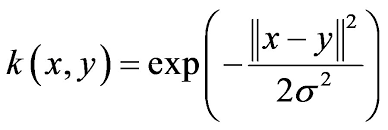

El siguiente diagrama muestra un ejemplo de clasificación SVM con núcleo RBF.

### Clasificación SVM con núcleo RBF

![Clasificación con núcleo RBF](https://www.researchgate.net/profile/Periklis_Gogas/publication/286180566/figure/fig5/AS:304327777374210@1449568804246/An-example-of-an-SVM-classification-using-the-RBF-kernel-The-two-classes-are-separated.png)

## **3.4 Núcleo sigmoide**

El núcleo sigmoide tiene origen en redes neuronales y puede interpretarse como un análogo. Tiene la forma:

**Núcleo sigmoide: k(x, y) = tanh(α xᵀy + c)**

Ilustración conceptual del núcleo sigmoide:

### Núcleo sigmoide

![Núcleo sigmoide](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTKeXbOIlniBXYwMYlEYLKPwZZg8vFU1wVm3RWMACjVcT4iBVDy&s)

# **4. SVM en Scikit-Learn** <a class="anchor" id="4"></a>

[Índice](#0.1)

Scikit-Learn ofrece herramientas listas para entrenar SVM. Para **clasificación**, las más relevantes son:

- **`LinearSVC`**: solo separación lineal (no se pasa `kernel`; está pensado para problemas lineales).

- **`SVC`** y **`NuSVC`**: clasificación con distintos núcleos. **`NuSVC`** controla el número de vectores de soporte mediante un parámetro ν. En **`SVC`** se suelen fijar `kernel`, `gamma` y `C` (entre otros). Por defecto, `kernel='rbf'`, pero puede usarse `'poly'`, `'linear'`, `'sigmoid'` o un núcleo personalizado.



# **5. Descripción del conjunto de datos** <a class="anchor" id="5"></a>

[Índice](#0.1)

Se utiliza el conjunto **Predicting a Pulsar Star** (HTRU2).

Los púlsares son un tipo poco frecuente de estrellas de neutrones que emiten en radio y pueden detectarse desde la Tierra. Interesan como sondas del espacio-tiempo, el medio interestelar y el estado de la materia. En este problema la detección se formula como **clasificación binaria**: la clase positiva (minoritaria) son púlsares reales y la negativa (mayoritaria) candidatos espurios por RFI/ruido.

El conjunto incluye 16.259 ejemplos espurios y 1.639 púlsares reales. Cada fila contiene primero las variables y al final la etiqueta de clase: **0** (negativo) y **1** (positivo).

### Información de los atributos

Cada candidato se describe con **8 variables continuas** y **una variable de clase**. Las cuatro primeras son estadísticos del perfil de pulso integrado; las cuatro siguientes provienen de la curva DM-SNR (*dispersion measure – signal-to-noise ratio*). Resumen:

1. Media del perfil integrado.
2. Desviación típica del perfil integrado.
3. Curtosis en exceso del perfil integrado.
4. Asimetría (*skewness*) del perfil integrado.
5. Media de la curva DM-SNR.
6. Desviación típica de la curva DM-SNR.
7. Curtosis en exceso de la curva DM-SNR.
8. Asimetría de la curva DM-SNR.
9. Clase (`target_class`).

# **6. Importar librerías** <a class="anchor" id="6"></a>

[Índice](#0.1)

En **Google Colab**, `numpy`, `pandas`, `matplotlib`, `seaborn` y `scikit-learn` suelen estar ya instalados. A continuación se importan las necesarias para el análisis.

In [ ]:
# Google Colab incluye NumPy, pandas, matplotlib, seaborn y scikit-learn.
# Si ejecuta este cuaderno fuera de Colab, instale las dependencias con pip según su entorno.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# --- Ruta al archivo CSV (ajuste si es necesario) ---
# Opción A: Subir el archivo con el menú Entorno de ejecución → Subir al almacenamiento de sesión
#           y dejarlo como /content/pulsar_stars.csv
# Opción B: from google.colab import files
#           uploaded = files.upload()
#           # Tras subir, suele quedar en /content/pulsar_stars.csv
# Opción C: Montar Google Drive y poner aquí la ruta al CSV en su Drive.

RUTA_CSV = "/content/pulsar_stars.csv"

if not os.path.isfile(RUTA_CSV):
    raise FileNotFoundError(
        "No se encuentra el archivo CSV. Descargue pulsar_stars.csv (misma carpeta Data del curso), "
        "suba la sesión de Colab o asigne la ruta correcta a RUTA_CSV."
    )


In [ ]:
import warnings

# Silenciar avisos no críticos durante la ejecución
warnings.filterwarnings('ignore')


# **7. Cargar el conjunto de datos** <a class="anchor" id="7"></a>

[Índice](#0.1)

In [ ]:
df = pd.read_csv(RUTA_CSV)


# **8. Análisis exploratorio** <a class="anchor" id="8"></a>

[Índice](#0.1)

Se exploran dimensiones, nombres de columnas, valores faltantes y distribuciones.

In [ ]:
# Dimensiones del DataFrame

df.shape


Hay **17.898** filas y **9** columnas.

In [ ]:
# Vista previa

df.head()


Hay **9** variables: **8** continuas y **1** discreta. La variable discreta es `target_class`, que es la **variable objetivo**.

A continuación se revisan los nombres de columna por si hubiera espacios sobrantes.

In [ ]:
# Nombres de columnas

col_names = df.columns
col_names


En los datos originales aparecen **espacios al inicio** en varios nombres de columna; conviene eliminarlos.

In [ ]:
# Eliminar espacios en los nombres de columnas

df.columns = df.columns.str.strip()


Se han eliminado los espacios iniciales. Comprobación de nombres:

In [ ]:
# Comprobar nombres

df.columns


Los nombres son muy largos; se acortan renombrando columnas (IP = *integrated profile*; DM-SNR = medida de dispersión y relación señal/ruido en la curva indicada).

In [ ]:
# Renombrar columnas (abreviaturas)

df.columns = ['IP Mean', 'IP Sd', 'IP Kurtosis', 'IP Skewness',
              'DM-SNR Mean', 'DM-SNR Sd', 'DM-SNR Kurtosis', 'DM-SNR Skewness', 'target_class']


In [ ]:
# Nombres tras el renombrado

df.columns


Los nombres quedan abreviados: **IP** corresponde al perfil integrado y **DM-SNR** a la curva DM-SNR. Así es más cómodo trabajar en el resto del cuaderno.

La variable objetivo es `target_class`. Se revisa su distribución de frecuencias.

In [ ]:
# Distribución de frecuencias de la variable objetivo

df['target_class'].value_counts()


In [ ]:
# Porcentajes por clase

df['target_class'].value_counts() / float(len(df))


Aproximadamente **90,84 %** de observaciones son clase **0** y **9,16 %** clase **1**: hay **desbalance de clases**. Las métricas más allá de la simple exactitud se comentan más adelante.

In [ ]:
# Resumen del DataFrame

df.info()


No hay valores faltantes y todas las variables son numéricas.

### Valores faltantes por variable

In [ ]:
# Valores faltantes por columna

df.isnull().sum()


No hay valores faltantes.

### Resumen de variables numéricas

- Hay **9** variables numéricas.
- **8** continuas y **1** discreta (`target_class`, objetivo).
- No hay valores faltantes.

### Valores atípicos en variables continuas

In [ ]:
# Estadísticos descriptivos (redondeados)

round(df.describe(), 2)


Los estadísticos sugieren **valores atípicos** en varias variables continuas.

Se usan diagramas de caja para visualizarlos.

In [ ]:
# Diagramas de caja para detectar valores atípicos

plt.figure(figsize=(24, 20))

plt.subplot(4, 2, 1)
fig = df.boxplot(column='IP Mean')
fig.set_title('')
fig.set_ylabel('IP Mean')

plt.subplot(4, 2, 2)
fig = df.boxplot(column='IP Sd')
fig.set_title('')
fig.set_ylabel('IP Sd')

plt.subplot(4, 2, 3)
fig = df.boxplot(column='IP Kurtosis')
fig.set_title('')
fig.set_ylabel('IP Kurtosis')

plt.subplot(4, 2, 4)
fig = df.boxplot(column='IP Skewness')
fig.set_title('')
fig.set_ylabel('IP Skewness')

plt.subplot(4, 2, 5)
fig = df.boxplot(column='DM-SNR Mean')
fig.set_title('')
fig.set_ylabel('DM-SNR Mean')

plt.subplot(4, 2, 6)
fig = df.boxplot(column='DM-SNR Sd')
fig.set_title('')
fig.set_ylabel('DM-SNR Sd')

plt.subplot(4, 2, 7)
fig = df.boxplot(column='DM-SNR Kurtosis')
fig.set_title('')
fig.set_ylabel('DM-SNR Kurtosis')

plt.subplot(4, 2, 8)
fig = df.boxplot(column='DM-SNR Skewness')
fig.set_title('')
fig.set_ylabel('DM-SNR Skewness')


Los diagramas de caja confirman la presencia de numerosos **valores atípicos** en estas variables.

### Valores atípicos y las SVM

Existen formulaciones **de margen duro** y **de margen suave**. El margen duro no tolera errores de clasificación en el entrenamiento. El **margen suave** permite algunos puntos mal clasificados o dentro del margen; el parámetro **C** penaliza esas violaciones. **C bajo** admite más “atípicos” respecto al margen; **C alto** los penaliza más.

Con datos ruidosos o con outliers, suele ser razonable probar **valores de C altos** al ajustar el modelo.

### Distribución de las variables

Histogramas para comprobar si las distribuciones son simétricas o sesgadas.

In [ ]:
# Histogramas de las variables continuas

plt.figure(figsize=(24, 20))

plt.subplot(4, 2, 1)
fig = df['IP Mean'].hist(bins=20)
fig.set_xlabel('IP Mean')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 2)
fig = df['IP Sd'].hist(bins=20)
fig.set_xlabel('IP Sd')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 3)
fig = df['IP Kurtosis'].hist(bins=20)
fig.set_xlabel('IP Kurtosis')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 4)
fig = df['IP Skewness'].hist(bins=20)
fig.set_xlabel('IP Skewness')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 5)
fig = df['DM-SNR Mean'].hist(bins=20)
fig.set_xlabel('DM-SNR Mean')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 6)
fig = df['DM-SNR Sd'].hist(bins=20)
fig.set_xlabel('DM-SNR Sd')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 7)
fig = df['DM-SNR Kurtosis'].hist(bins=20)
fig.set_xlabel('DM-SNR Kurtosis')
fig.set_ylabel('Número de candidatos')

plt.subplot(4, 2, 8)
fig = df['DM-SNR Skewness'].hist(bins=20)
fig.set_xlabel('DM-SNR Skewness')
fig.set_ylabel('Número de candidatos')


Las ocho variables continuas muestran **asimetría** (distribuciones sesgadas).

# **9. Matriz de características y variable objetivo** <a class="anchor" id="9"></a>

[Índice](#0.1)

In [ ]:
X = df.drop(['target_class'], axis=1)

y = df['target_class']


# **10. Partición en entrenamiento y prueba** <a class="anchor" id="10"></a>

[Índice](#0.1)

In [ ]:
# Partición entrenamiento / prueba (80 % - 20 %)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


In [ ]:
# Tamaños de los conjuntos

X_train.shape, X_test.shape


# **11. Escalado de características** <a class="anchor" id="11"></a>

[Índice](#0.1)

In [ ]:
cols = X_train.columns


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


In [ ]:
X_train = pd.DataFrame(X_train, columns=[cols])


In [ ]:
X_test = pd.DataFrame(X_test, columns=[cols])


In [ ]:
X_train.describe()


`X_train` y `X_test` están escalados y listos para entrenar el clasificador SVM (los mismos pasos servirían antes de otros modelos lineales o basados en distancias).

# **12. SVM con hiperparámetros por defecto** <a class="anchor" id="12"></a>

[Índice](#0.1)

Por defecto en `SVC`: **C=1.0**, **kernel='rbf'** y **gamma='scale'** (en versiones recientes; antes a veces `'auto'`).

In [ ]:
# Clasificador SVC con hiperparámetros por defecto
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svc = SVC()
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)

print('Exactitud del modelo (hiperparámetros por defecto): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### SVM con núcleo RBF y C=100.0

Dado que hay valores atípicos, conviene probar **C** más alto (menos tolerancia a puntos mal clasificados en el margen suave). Se entrena con **RBF** y **C=100.0**.

In [ ]:
# Núcleo RBF y C=100
svc = SVC(C=100.0)
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)

print('Exactitud (RBF, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


Con **C=100.0** suele obtenerse mayor exactitud en prueba que con **C=1.0**. Se prueba también **C=1000.0**.

### SVM con núcleo RBF y C=1000.0


In [ ]:
# Núcleo RBF y C=1000
svc = SVC(C=1000.0)
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)

print('Exactitud (RBF, C=1000.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


En este conjunto, **C=1000.0** puede **reducir** la exactitud en prueba respecto a **C=100.0** (posible sobreajuste o interacción con el escalado).

# **13. SVM con núcleo lineal** <a class="anchor" id="13"></a>

[Índice](#0.1)

### SVM lineal con C=1.0

In [ ]:
# Núcleo lineal, C=1.0
linear_svc = SVC(kernel='linear', C=1.0)
linear_svc.fit(X_train, y_train)
y_pred_test = linear_svc.predict(X_test)

print('Exactitud (lineal, C=1.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred_test)))


### SVM lineal con C=100.0

In [ ]:
# Núcleo lineal, C=100.0
linear_svc100 = SVC(kernel='linear', C=100.0)
linear_svc100.fit(X_train, y_train)
y_pred = linear_svc100.predict(X_test)

print('Exactitud (lineal, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### SVM lineal con C=1000.0

In [ ]:
# Núcleo lineal, C=1000.0
linear_svc1000 = SVC(kernel='linear', C=1000.0)
linear_svc1000.fit(X_train, y_train)
y_pred = linear_svc1000.predict(X_test)

print('Exactitud (lineal, C=1000.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


Con núcleo lineal, **C=100.0** y **C=1000.0** suelen mejorar respecto a **C=1.0** en este problema.

Aquí **`y_test`** son las etiquetas reales en prueba y **`y_pred_test`** las predichas por el modelo lineal con **C=1.0** (variable `linear_svc`).

### Comparar exactitud en entrenamiento y en prueba

Se comprueba si hay sobreajuste comparando el rendimiento en train y test.

In [ ]:
y_pred_train = linear_svc.predict(X_train)

y_pred_train


In [ ]:
print('Exactitud en entrenamiento: {0:0.4f}'.format(accuracy_score(y_train, y_pred_train)))


Las exactitudes en entrenamiento y prueba son **parecidas** (sin señal clara de sobreajuste fuerte).

### Sobreajuste y subajuste

In [ ]:
print('Puntuación en entrenamiento: {:.4f}'.format(linear_svc.score(X_train, y_train)))
print('Puntuación en prueba: {:.4f}'.format(linear_svc.score(X_test, y_test)))


Las puntuaciones en entrenamiento y prueba son coherentes; no parece un caso extremo de sobreajuste solo por esta comparación.


### Comparar con la exactitud nula (*null accuracy*)

La exactitud del modelo debe compararse con la **exactitud nula**: la que se obtendría prediciendo siempre la **clase más frecuente** en el conjunto de prueba.

Primero, distribución de clases en **test**:

In [ ]:
# Distribución de clases en el conjunto de prueba

y_test.value_counts()


La clase **0** es la más frecuente en prueba (3306 frente a 274). La exactitud nula es aproximadamente 3306/(3306+274).

In [ ]:
# Exactitud nula (siempre predecir la clase mayoritaria)

null_accuracy = (3306 / (3306 + 274))

print('Exactitud nula: {0:0.4f}'.format(null_accuracy))


La exactitud del modelo supera claramente la exactitud nula; el clasificador SVM aporta información más allá de predecir siempre la mayoría.

# **14. SVM con núcleo polinomial** <a class="anchor" id="14"></a>

[Índice](#0.1)

### Núcleo polinomial con C=1.0

In [ ]:
# Núcleo polinomial, C=1.0
poly_svc = SVC(kernel='poly', C=1.0)
poly_svc.fit(X_train, y_train)
y_pred = poly_svc.predict(X_test)

print('Exactitud (polinomial, C=1.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### Núcleo polinomial con C=100.0

In [ ]:
# Núcleo polinomial, C=100.0
poly_svc100 = SVC(kernel='poly', C=100.0)
poly_svc100.fit(X_train, y_train)
y_pred = poly_svc100.predict(X_test)

print('Exactitud (polinomial, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


El núcleo polinomial rinde peor aquí; podría estar **sobreajustando** el entrenamiento.

# **15. SVM con núcleo sigmoide** <a class="anchor" id="15"></a>

[Índice](#0.1)

### Núcleo sigmoide con C=1.0

In [ ]:
# Núcleo sigmoide, C=1.0
sigmoid_svc = SVC(kernel='sigmoid', C=1.0)
sigmoid_svc.fit(X_train, y_train)
y_pred = sigmoid_svc.predict(X_test)

print('Exactitud (sigmoide, C=1.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### Núcleo sigmoide con C=100.0

In [ ]:
# Núcleo sigmoide, C=100.0
sigmoid_svc100 = SVC(kernel='sigmoid', C=100.0)
sigmoid_svc100.fit(X_train, y_train)
y_pred = sigmoid_svc100.predict(X_test)

print('Exactitud (sigmoide, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


El núcleo sigmoide también rinde peor que RBF o lineal en este caso, de forma similar al polinomial.

### Comentarios

Las mejores exactitudes en este cuaderno suelen obtenerse con **RBF** o **lineal** y **C=100.0** (del orden de **0,983** en prueba). Sin embargo, con **clases desbalanceadas** la **exactitud** puede ser engañosa.

Conviene analizar la **matriz de confusión** y otras métricas (recall, precisión, F1, AUC) para entender errores en la clase minoritaria.

# **16. Matriz de confusión** <a class="anchor" id="16"></a>

[Índice](#0.1)

La **matriz de confusión** resume aciertos y errores por clase: verdaderos positivos (VP), verdaderos negativos (VN), falsos positivos (FP) y falsos negativos (FN).

- **VP**: predicho positivo y real positivo.
- **VN**: predicho negativo y real negativo.
- **FP** (error tipo I): predicho positivo pero real negativo.
- **FN** (error tipo II): predicho negativo pero real positivo (suele ser crítico si el positivo es raro e importante).



In [ ]:
# Matriz de confusión
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test)

print('Matriz de confusión\n\n', cm)

print('\nVerdaderos positivos (VP) = ', cm[0, 0])
print('\nVerdaderos negativos (VN) = ', cm[1, 1])
print('\nFalsos positivos (FP) = ', cm[0, 1])
print('\nFalsos negativos (FN) = ', cm[1, 0])


En el ejemplo del cuaderno (predicciones `y_pred_test` del SVM lineal C=1.0), la matriz muestra muchos aciertos y pocos errores; los valores concretos dependen de la ejecución aleatoria (semilla de partición **random_state=0**).

Revise en su salida los recuentos VP, VN, FP y FN.

In [ ]:
# Mapa de calor de la matriz de confusión

cm_matrix = pd.DataFrame(
    data=cm,
    columns=['Real positivo:1', 'Real negativo:0'],
    index=['Predicho positivo:1', 'Predicho negativo:0'],
)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')


# **17. Métricas de clasificación** <a class="anchor" id="17"></a>

[Índice](#0.1)

### Informe de clasificación

El **classification_report** de scikit-learn muestra **precisión**, **exhaustividad** (*recall*), **F1** y **soporte** por clase.

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_test))


### Exactitud de clasificación

In [ ]:
TP = cm[0, 0]
TN = cm[1, 1]
FP = cm[0, 1]
FN = cm[1, 0]


In [ ]:
# Exactitud de clasificación

classification_accuracy = (TP + TN) / float(TP + TN + FP + FN)

print('Exactitud de clasificación: {0:0.4f}'.format(classification_accuracy))


### Error de clasificación

In [ ]:
# Tasa de error de clasificación

classification_error = (FP + FN) / float(TP + TN + FP + FN)

print('Error de clasificación: {0:0.4f}'.format(classification_error))


### Precisión

Proporción de predicciones positivas correctas entre todas las predichas como positivas: VP / (VP + FP).

In [ ]:
# Precisión

precision = TP / float(TP + FP)

print('Precisión: {0:0.4f}'.format(precision))


### Exhaustividad (*recall*)

Proporción de positivos reales detectados: VP / (VP + FN). También se llama **sensibilidad**.

In [ ]:
recall = TP / float(TP + FN)

print('Exhaustividad (recall): {0:0.4f}'.format(recall))


### Tasa de verdaderos positivos

Coincide con la **exhaustividad** (*recall*).

In [ ]:
true_positive_rate = TP / float(TP + FN)

print('Tasa de verdaderos positivos: {0:0.4f}'.format(true_positive_rate))


### Tasa de falsos positivos

In [ ]:
false_positive_rate = FP / float(FP + TN)

print('Tasa de falsos positivos: {0:0.4f}'.format(false_positive_rate))


### Especificidad

VN / (VN + FP).

In [ ]:
specificity = TN / (TN + FP)

print('Especificidad: {0:0.4f}'.format(specificity))


### Puntuación F1

Media armónica de precisión y exhaustividad; equilibra ambos criterios. El valor va de 0 a 1.

### Soporte (*support*)

Número de ejemplos reales de cada clase en el conjunto usado (aquí, prueba).

# **18. Curva ROC y AUC** <a class="anchor" id="18"></a>

[Índice](#0.1)

### Curva ROC

La **curva ROC** (*Receiver Operating Characteristic*) representa la **tasa de verdaderos positivos** frente a la **tasa de falsos positivos** al variar el umbral de decisión (en modelos que producen puntuaciones o probabilidades; aquí las predicciones son duras, pero la curva ilustra el concepto en el flujo del tutorial original).

La **TPR** coincide con la sensibilidad; la **FPR** es FP / (FP + VN).



In [ ]:
# Curva ROC (nota: con predicciones discretas la curva puede verse simplificada)
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_pred_test)

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, linewidth=2)
plt.plot([0, 1], [0, 1], 'k--')
plt.rcParams['font.size'] = 12

plt.title('Curva ROC — clasificador de púlsares')
plt.xlabel('Tasa de falsos positivos (1 - especificidad)')
plt.ylabel('Tasa de verdaderos positivos (sensibilidad)')

plt.show()


La curva ROC ayuda a razonar sobre el equilibrio entre sensibilidad y especificidad según el umbral.

### AUC-ROC

El **área bajo la curva ROC (AUC)** resume el rendimiento: **1** sería un clasificador perfecto en ese gráfico; **0,5** correspondería a azar. Valores altos indican buena capacidad de separación entre clases.

In [ ]:
# AUC-ROC
from sklearn.metrics import roc_auc_score

ROC_AUC = roc_auc_score(y_test, y_pred_test)

print('AUC-ROC: {:.4f}'.format(ROC_AUC))


### Comentarios

- El **AUC** resume el comportamiento del clasificador en distintos umbrales.
- Un **AUC** cercano a **1** indica buen poder discriminativo entre clases en este problema.

In [ ]:
# AUC-ROC con validación cruzada (entrenamiento)
from sklearn.model_selection import cross_val_score

Cross_validated_ROC_AUC = cross_val_score(linear_svc, X_train, y_train, cv=10, scoring='roc_auc').mean()

print('AUC-ROC (validación cruzada, media): {:.4f}'.format(Cross_validated_ROC_AUC))


# **19. Validación cruzada k-fold con mezcla** <a class="anchor" id="19"></a>

[Índice](#0.1)

La validación cruzada k-fold estima el rendimiento promedio del modelo. Con **clases desbalanceadas**, lo ideal es usar **`StratifiedKFold`** para mantener la proporción de clases en cada pliegue. El tutorial original usa **`KFold`** con `shuffle=True` (el título menciona “estratificado”, pero el código es k-fold estándar con mezcla).

Aquí se **replica el mismo código** que el tutorial para comparar resultados; si lo desea, sustituya `KFold` por `StratifiedKFold` del mismo modo.

### Validación cruzada con núcleo lineal (`KFold`, shuffle)

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=0)

linear_svc = SVC(kernel='linear')

linear_scores = cross_val_score(linear_svc, X, y, cv=kfold)


In [ ]:
# Puntuaciones de validación cruzada (núcleo lineal)

print('Puntuaciones de validación cruzada (lineal):\n\n{}'.format(linear_scores))


In [ ]:
# Media de las puntuaciones (lineal)

print('Media (lineal): {:.4f}'.format(linear_scores.mean()))


### Validación cruzada con núcleo RBF

In [ ]:
rbf_svc = SVC(kernel='rbf')

rbf_scores = cross_val_score(rbf_svc, X, y, cv=kfold)


In [ ]:
# Puntuaciones de validación cruzada (RBF)

print('Puntuaciones de validación cruzada (RBF):\n\n{}'.format(rbf_scores))


In [ ]:
# Media de las puntuaciones (RBF)

print('Media (RBF): {:.4f}'.format(rbf_scores.mean()))


La media de las puntuaciones en validación cruzada puede ser algo menor que la exactitud en un único split entrenamiento/prueba; es normal. Para datos desbalanceados, valore métricas por clase o **AUC** además de la exactitud.

# **20. Optimización de hiperparámetros con GridSearchCV** <a class="anchor" id="20"></a>

[Índice](#0.1)

In [ ]:
# Búsqueda en rejilla de hiperparámetros
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

svc = SVC()

parameters = [
    {'C': [1, 10, 100, 1000], 'kernel': ['linear']},
    {
        'C': [1, 10, 100, 1000],
        'kernel': ['rbf'],
        'gamma': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    },
    {
        'C': [1, 10, 100, 1000],
        'kernel': ['poly'],
        'degree': [2, 3, 4],
        'gamma': [0.01, 0.02, 0.03, 0.04, 0.05],
    },
]

grid_search = GridSearchCV(
    estimator=svc,
    param_grid=parameters,
    scoring='accuracy',
    cv=5,
    verbose=0,
)

grid_search.fit(X_train, y_train)


In [ ]:
# Mejor modelo según GridSearchCV

print('Mejor puntuación (validación cruzada en entrenamiento): {:.4f}\n\n'.format(grid_search.best_score_))

print('Mejores hiperparámetros:', '\n\n', grid_search.best_params_)

print('\n\nMejor estimador:', '\n\n', grid_search.best_estimator_)


In [ ]:
# Exactitud del mejor estimador en el conjunto de prueba

print('Exactitud en prueba (mejor modelo): {0:0.4f}'.format(grid_search.score(X_test, y_test)))


### Comentarios

- La exactitud en el conjunto de prueba del modelo afinado puede ser muy cercana a la del modelo inicial.
- **GridSearchCV** ayuda a explorar combinaciones de `C`, `kernel`, `gamma`, etc.
- No confunda **`best_score_`** (media de validación cruzada en entrenamiento) con **`score(X_test, y_test)`** (rendimiento en el conjunto de prueba reservado).

# **21. Resultados y conclusiones** <a class="anchor" id="21"></a>

[Índice](#0.1)

1. Hay **valores atípicos**; aumentar **C** puede cambiar la exactitud según el núcleo y el grado de sobreajuste.

2. Con **RBF** y **lineal** y **C=100.0** se obtienen unas de las mejores exactitudes en este flujo; ante **desbalance**, la exactitud no basta: revisar **matriz de confusión**, **F1** y **AUC**.

3. El **AUC-ROC** alto sugiere buen poder discriminativo global.

4. La validación cruzada con **`KFold`** da una estimación más estable; con clases desbalanceadas considere **`StratifiedKFold`**.

5. **GridSearchCV** permite afinar hiperparámetros; compare siempre con un conjunto de prueba independiente.

# **22. Referencias** <a class="anchor" id="22"></a>

[Índice](#0.1)

Material de apoyo y lecturas recomendadas:

1. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* — Aurélien Géron  
2. *Introduction to Machine Learning with Python* — Andreas C. Müller y Sarah Guido  
3. Cursos en línea sobre aprendizaje automático y *feature engineering* (por ejemplo plataformas tipo Udemy)  
4. https://en.wikipedia.org/wiki/Support-vector_machine  
5. https://www.datacamp.com/community/tutorials/svm-classification-scikit-learn-python  
6. https://en.wikipedia.org/wiki/Kernel_method  
7. https://en.wikipedia.org/wiki/Polynomial_kernel  
8. https://en.wikipedia.org/wiki/Radial_basis_function_kernel  



Fin del cuaderno. Compruebe que ha subido `pulsar_stars.csv` y que las rutas coinciden con su sesión de Colab.

Comentarios y mejoras: material de clase ML Finanzas.

[Volver al inicio](#0)